# Prévision des ventes de boulangerie 

Ce notebook repart du fichier brut `Bakery sales.xlsx` et produit des données propres, des features temporelles sans fuite, une validation chronologique, une baseline, des modèles XGBoost et LightGBM, des métriques, des graphiques et des prévisions futures.

**Hypothèse documentée :** une date absente du fichier correspond à un jour sans vente et reçoit donc un CA nul. Cette hypothèse doit être confirmée avec le contexte métier.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style='whitegrid', palette='deep')

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == 'notebooks' else NOTEBOOK_DIR
RAW_FILE = PROJECT_ROOT / 'data' / 'Bakery sales.xlsx'
EXPORT_DIR = PROJECT_ROOT / 'outputs' / 'exports'
PLOT_DIR = PROJECT_ROOT / 'outputs' / 'plots'
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)
print(f'Fichier source : {RAW_FILE}')
print(f'Exports : {EXPORT_DIR}')
print(f'Graphiques : {PLOT_DIR}')

Fichier source : d:\projet_2026\bakery-sales-forecast-main\bakery-sales-forecast\data\Bakery sales.xlsx
Exports : d:\projet_2026\bakery-sales-forecast-main\bakery-sales-forecast\outputs\exports
Graphiques : d:\projet_2026\bakery-sales-forecast-main\bakery-sales-forecast\outputs\plots


## 1. Chargement et nettoyage des transactions

In [2]:
raw = pd.read_excel(RAW_FILE)
raw.columns = raw.columns.str.strip().str.lower()
raw = raw.rename(columns={'quantit': 'quantity', 'unit_pric': 'unit_price'})
raw['date'] = pd.to_datetime(raw['date'], errors='coerce')
raw['unit_price'] = (
    raw['unit_price'].astype(str)
    .str.replace('€', '', regex=False)
    .str.replace(' ', '', regex=False)
    .str.replace(',', '.', regex=False)
)
raw['unit_price'] = pd.to_numeric(raw['unit_price'], errors='coerce')
raw['quantity'] = pd.to_numeric(raw['quantity'], errors='coerce')
raw['article'] = raw['article'].astype('string').str.strip().str.upper()
raw = raw.dropna(subset=['date', 'quantity', 'unit_price', 'ticket_number'])
invalid_rows = ((raw['quantity'] <= 0) | (raw['unit_price'] <= 0)).sum()
raw = raw[(raw['quantity'] > 0) & (raw['unit_price'] > 0)].copy()
raw['montant_total'] = raw['quantity'] * raw['unit_price']
raw.to_excel(EXPORT_DIR / 'transactions_nettoyees.xlsx', index=False)
print(f'Transactions initiales : {len(pd.read_excel(RAW_FILE)):,}')
print(f'Lignes invalides exclues : {invalid_rows:,}')
print(f'Transactions conservees : {len(raw):,}')
print(f'Periode : {raw.date.min().date()} -> {raw.date.max().date()}')

Transactions initiales : 234,005
Lignes invalides exclues : 1,326
Transactions conservees : 232,679
Periode : 2021-01-02 -> 2022-09-30


## 2. Agrégation journalière et traitement des dates manquantes

In [3]:
daily = (
    raw.groupby('date', as_index=False)
    .agg(
        CA_total=('montant_total', 'sum'),
        nb_articles=('quantity', 'sum'),
        nb_transactions=('ticket_number', 'nunique'),
        prix_moyen=('unit_price', 'mean')
    )
)
calendar = pd.date_range(daily['date'].min(), daily['date'].max(), freq='D')
daily = daily.set_index('date').reindex(calendar).rename_axis('date').reset_index()
daily['jour_observe'] = daily['CA_total'].notna().astype(int)
zero_columns = ['CA_total', 'nb_articles', 'nb_transactions']
daily[zero_columns] = daily[zero_columns].fillna(0)
daily['prix_moyen'] = daily['prix_moyen'].fillna(0)
daily.to_excel(EXPORT_DIR / 'ventes_journalieres_completes.xlsx', index=False)
print(f'Jours observes : {daily.jour_observe.sum():,}')
print(f'Jours du calendrier complet : {len(daily):,}')
print(f'Jours ajoutes comme jours sans ventes : {(daily.jour_observe == 0).sum():,}')
daily.head()

Jours observes : 600
Jours du calendrier complet : 637
Jours ajoutes comme jours sans ventes : 37


,date,CA_total,nb_articles,nb_transactions,prix_moyen,jour_observe
0,2021-01-02,987.85,580.00,184.00,1.97,1
1,2021-01-03,1015.20,565.00,218.00,2.09,1
2,2021-01-04,461.90,315.00,144.00,1.62,1
3,2021-01-05,526.10,312.00,149.00,1.79,1
4,2021-01-06,0.00,0.00,0.00,0.00,0


## 3. Analyse visuelle de la série

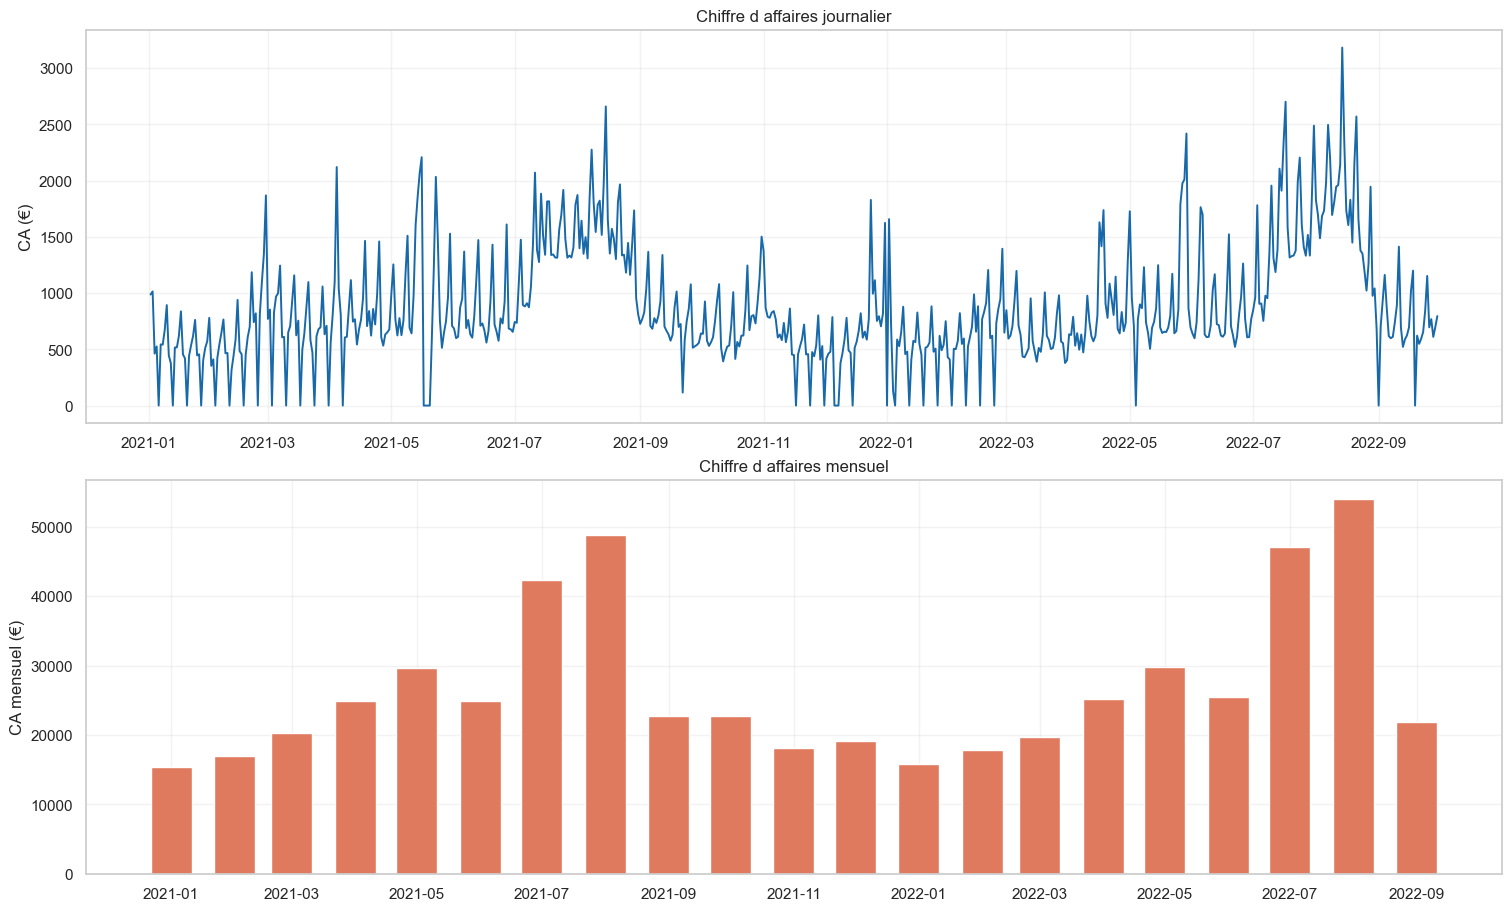

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9), constrained_layout=True)
axes[0].plot(daily['date'], daily['CA_total'], color='#1769aa', linewidth=1.4)
axes[0].set_title('Chiffre d affaires journalier')
axes[0].set_ylabel('CA (€)')
monthly = daily.set_index('date')['CA_total'].resample('MS').sum()
axes[1].bar(monthly.index, monthly.values, width=20, color='#e07a5f')
axes[1].set_title('Chiffre d affaires mensuel')
axes[1].set_ylabel('CA mensuel (€)')
for ax in axes:
    ax.grid(alpha=0.25)
fig.savefig(PLOT_DIR / '01_evolution_ca.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. Features calendrier, lags et moyennes mobiles sans fuite

In [5]:
df = daily.copy()
df['annee'] = df['date'].dt.year
df['mois'] = df['date'].dt.month
df['jour'] = df['date'].dt.day
df['jour_semaine'] = df['date'].dt.weekday
df['est_weekend'] = (df['jour_semaine'] >= 5).astype(int)
df['trimestre'] = df['date'].dt.quarter
df['semaine'] = df['date'].dt.isocalendar().week.astype(int)
df['jour_annee'] = df['date'].dt.dayofyear

# Les lags utilisent le calendrier complet : shift(7) signifie bien J-7.
for lag in [1, 7, 14, 30]:
    df[f'lag_{lag}'] = df['CA_total'].shift(lag)

# shift(1) exclut le CA du jour a predire.
for window in [7, 14, 30]:
    df[f'rolling_mean_{window}'] = (
        df['CA_total'].shift(1).rolling(window=window, min_periods=window).mean()
    )

features = [
    'annee', 'mois', 'jour', 'jour_semaine', 'est_weekend',
    'trimestre', 'semaine', 'jour_annee', 'lag_1', 'lag_7',
    'lag_14', 'lag_30', 'rolling_mean_7', 'rolling_mean_14',
    'rolling_mean_30'
]
df_ml = df.dropna(subset=features + ['CA_total']).reset_index(drop=True)
df_ml.to_excel(EXPORT_DIR / 'donnees_pretes_pour_ml.xlsx', index=False)
print(f'Donnees ML : {len(df_ml):,} lignes')
print(f'Features : {len(features)}')
df_ml[['date', 'CA_total', 'lag_7', 'rolling_mean_7']].head()

Donnees ML : 607 lignes
Features : 15


,date,CA_total,lag_7,rolling_mean_7
0,2021-02-01,353.40,446.30,452.76
1,2021-02-02,411.35,455.90,439.49
2,2021-02-03,0.00,0.00,433.12
3,2021-02-04,424.55,403.30,433.12
4,2021-02-05,543.45,512.70,436.16


## 5. Séparation temporelle et baseline

In [6]:
test_days = 60
split_date = df_ml['date'].max() - pd.Timedelta(days=test_days - 1)
train = df_ml[df_ml['date'] < split_date].copy()
test = df_ml[df_ml['date'] >= split_date].copy()
X_train, y_train = train[features], train['CA_total']
X_test, y_test = test[features], test['CA_total']

# Baseline : utiliser le CA du même jour de la semaine precedente.
baseline_pred = test['lag_7'].to_numpy()
print(f'Train : {train.date.min().date()} -> {train.date.max().date()} ({len(train)} jours)')
print(f'Test  : {test.date.min().date()} -> {test.date.max().date()} ({len(test)} jours)')

Train : 2021-02-01 -> 2022-08-01 (547 jours)
Test  : 2022-08-02 -> 2022-09-30 (60 jours)


## 6. XGBoost et LightGBM

In [7]:
models = {
    'Baseline_lag_7': None,
    'XGBoost': XGBRegressor(
        n_estimators=300, max_depth=5, learning_rate=0.04,
        subsample=0.85, colsample_bytree=0.85,
        objective='reg:squarederror', random_state=42, n_jobs=4
    ),
    'LightGBM': LGBMRegressor(
        n_estimators=300, max_depth=6, learning_rate=0.04,
        num_leaves=31, subsample=0.85, colsample_bytree=0.85,
        objective='regression', random_state=42, verbosity=-1
    )
}

predictions = {'Baseline_lag_7': baseline_pred}
for name, model in list(models.items())[1:]:
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

def metrics(y_true, y_pred):
    return {
        'MAE_euros': mean_absolute_error(y_true, y_pred),
        'RMSE_euros': np.sqrt(mean_squared_error(y_true, y_pred))
    }

metrics_df = pd.DataFrame({name: metrics(y_test, pred) for name, pred in predictions.items()}).T
metrics_df = metrics_df.sort_values('MAE_euros')
metrics_df.to_excel(EXPORT_DIR / 'comparaison_modeles.xlsx')
metrics_df

,MAE_euros,RMSE_euros
LightGBM,164.68,231.23
XGBoost,168.16,251.68
Baseline_lag_7,292.02,396.17


## 7. Résultats 

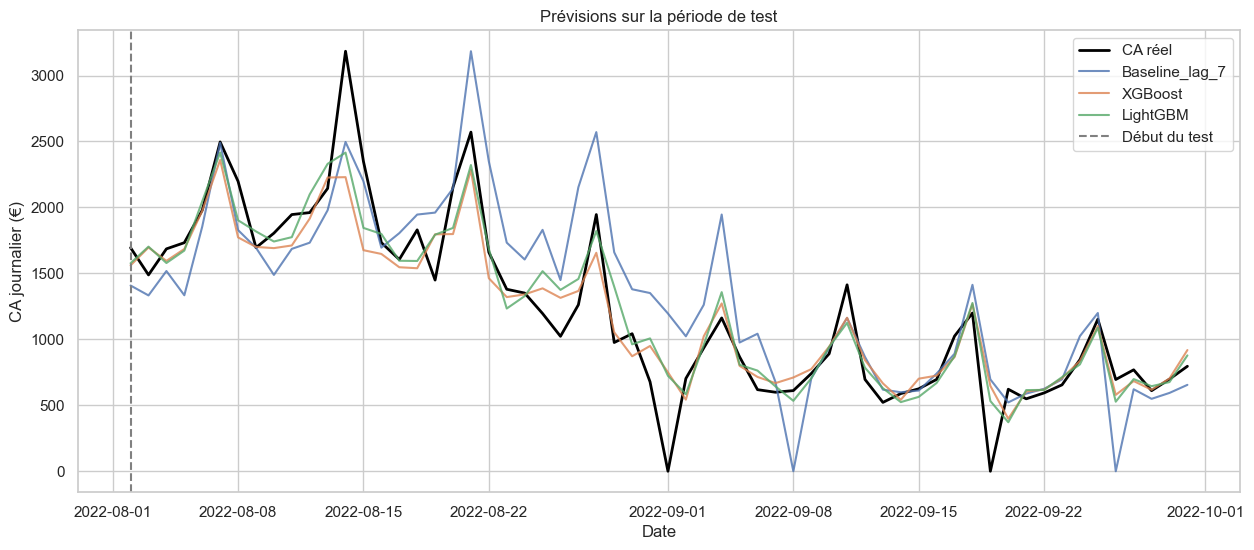

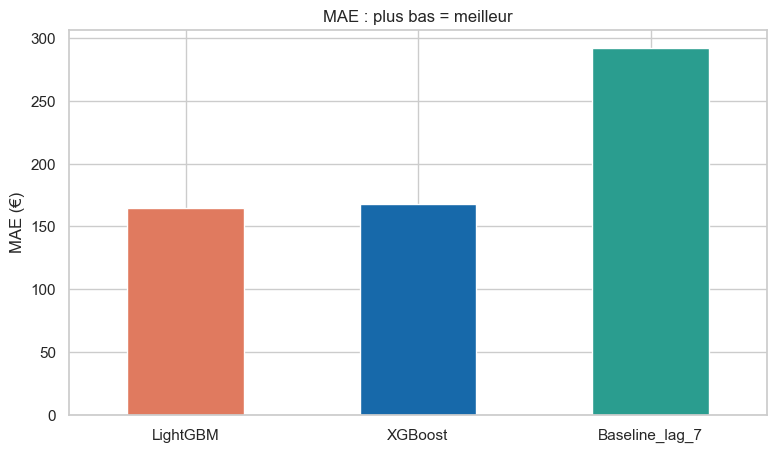

Fichiers utiles
01_evolution_ca.png
02_predictions_test.png
03_comparaison_mae.png
04_previsions_futures.png
Meilleur modèle selon le MAE : LightGBM


In [8]:
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(test['date'], y_test, label='CA réel', color='black', linewidth=2)
for name, pred in predictions.items():
    ax.plot(test['date'], pred, label=name, alpha=0.8)
ax.axvline(split_date, color='gray', linestyle='--', label='Début du test')
ax.set_title('Prévisions sur la période de test')
ax.set_xlabel('Date')
ax.set_ylabel('CA journalier (€)')
ax.legend()
fig.savefig(PLOT_DIR / '02_predictions_test.png', dpi=180, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
metrics_df['MAE_euros'].plot(kind='bar', ax=ax, color=['#e07a5f', '#1769aa', '#2a9d8f'])
ax.set_title('MAE : plus bas = meilleur')
ax.set_ylabel('MAE (€)')
ax.tick_params(axis='x', rotation=0)
fig.savefig(PLOT_DIR / '03_comparaison_mae.png', dpi=180, bbox_inches='tight')
plt.show()

print('Fichiers utiles')
for path in sorted(PLOT_DIR.glob('*.png')):
    print(path.name)
print('Meilleur modèle selon le MAE :', metrics_df.index[0])

## 8. Backtesting walk-forward

In [9]:
def walk_forward(model_factory, data, feature_names, initial_train_days=360, horizon=30, folds=3):
    rows = []
    for fold in range(folds):
        train_end = initial_train_days + fold * horizon
        test_end = train_end + horizon
        train_fold = data.iloc[:train_end]
        test_fold = data.iloc[train_end:test_end]
        if len(test_fold) < horizon:
            break
        model = model_factory()
        model.fit(train_fold[feature_names], train_fold['CA_total'])
        pred = model.predict(test_fold[feature_names])
        rows.append({
            'fold': fold + 1,
            'debut_test': test_fold['date'].min(),
            'fin_test': test_fold['date'].max(),
            'MAE_euros': mean_absolute_error(test_fold['CA_total'], pred),
            'RMSE_euros': np.sqrt(mean_squared_error(test_fold['CA_total'], pred))
        })
    return pd.DataFrame(rows)

backtest_xgb = walk_forward(
    lambda: XGBRegressor(n_estimators=250, max_depth=5, learning_rate=0.04, objective='reg:squarederror', random_state=42, n_jobs=4),
    df_ml, features
)
backtest_lgbm = walk_forward(
    lambda: LGBMRegressor(n_estimators=250, max_depth=6, learning_rate=0.04, num_leaves=31, objective='regression', random_state=42, verbosity=-1),
    df_ml, features
)
backtest_xgb['modele'] = 'XGBoost'
backtest_lgbm['modele'] = 'LightGBM'
backtest = pd.concat([backtest_xgb, backtest_lgbm], ignore_index=True)
backtest.to_excel(EXPORT_DIR / 'backtesting_walk_forward.xlsx', index=False)
backtest

,fold,debut_test,fin_test,MAE_euros,RMSE_euros,modele
0,1,2022-01-27,2022-02-25,108.59,143.21,XGBoost
1,2,2022-02-26,2022-03-27,103.66,153.45,XGBoost
2,3,2022-03-28,2022-04-26,203.20,285.64,XGBoost
3,1,2022-01-27,2022-02-25,95.73,118.83,LightGBM
4,2,2022-02-26,2022-03-27,110.33,151.11,LightGBM
5,3,2022-03-28,2022-04-26,169.36,267.77,LightGBM


## 9. Prévisions futures avec le meilleur modèle

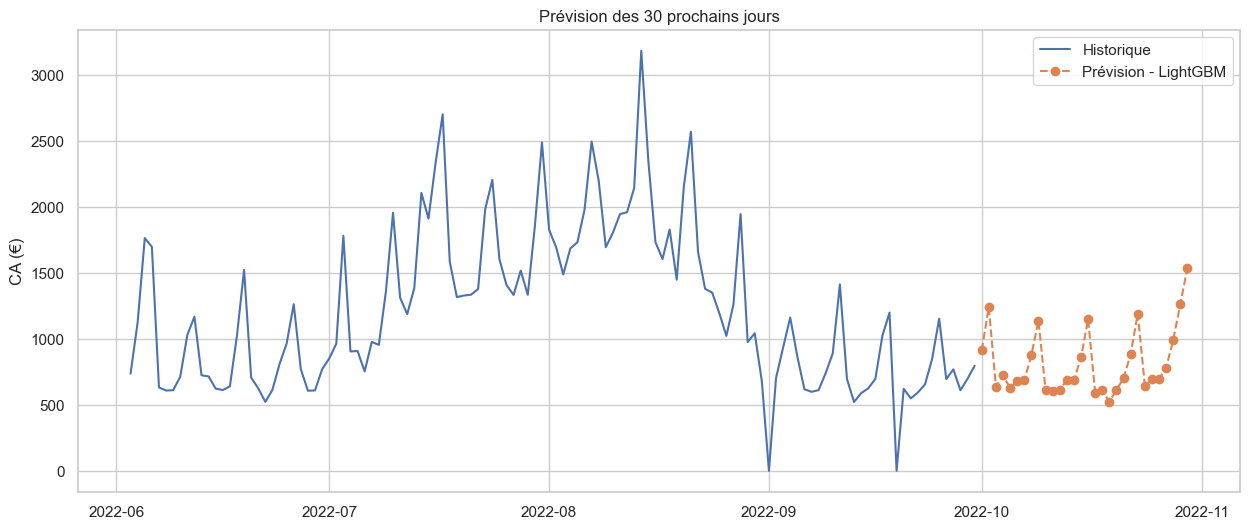

,date,CA_predit,modele
0,2022-10-01,912.60,LightGBM
1,2022-10-02,1240.58,LightGBM
2,2022-10-03,636.09,LightGBM
3,2022-10-04,724.11,LightGBM
4,2022-10-05,628.69,LightGBM


In [10]:
horizon = 30
best_name = metrics_df.index[0]
if best_name == 'Baseline_lag_7':
    final_model = None
else:
    final_model = models[best_name]
    final_model.fit(df_ml[features], df_ml['CA_total'])

history = df_ml[['date', 'CA_total']].copy()
future_dates = pd.date_range(history['date'].max() + pd.Timedelta(days=1), periods=horizon, freq='D')
future_rows = []

for future_date in future_dates:
    values = history['CA_total'].to_numpy()
    row = {
        'annee': future_date.year,
        'mois': future_date.month,
        'jour': future_date.day,
        'jour_semaine': future_date.weekday(),
        'est_weekend': int(future_date.weekday() >= 5),
        'trimestre': future_date.quarter,
        'semaine': int(future_date.isocalendar().week),
        'jour_annee': future_date.dayofyear,
        'lag_1': values[-1],
        'lag_7': values[-7],
        'lag_14': values[-14],
        'lag_30': values[-30],
        'rolling_mean_7': values[-7:].mean(),
        'rolling_mean_14': values[-14:].mean(),
        'rolling_mean_30': values[-30:].mean()
    }
    if final_model is None:
        prediction = row['lag_7']
    else:
        prediction = final_model.predict(pd.DataFrame([row])[features])[0]
    prediction = max(0, float(prediction))
    future_rows.append({'date': future_date, 'CA_predit': prediction, 'modele': best_name})
    history = pd.concat([history, pd.DataFrame({'date': [future_date], 'CA_total': [prediction]})], ignore_index=True)

future = pd.DataFrame(future_rows)
future.to_excel(EXPORT_DIR / 'previsions_30_jours.xlsx', index=False)
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(df_ml['date'].tail(120), df_ml['CA_total'].tail(120), label='Historique')
ax.plot(future['date'], future['CA_predit'], 'o--', label=f'Prévision - {best_name}')
ax.set_title('Prévision des 30 prochains jours')
ax.set_ylabel('CA (€)')
ax.legend()
fig.savefig(PLOT_DIR / '04_previsions_futures.png', dpi=180, bbox_inches='tight')
plt.show()
future.head()